In [4]:
import os
os.chdir('..')
print(os.getcwd())

c:\Users\Samiksha\Desktop\aiml-cie


In [5]:
import pandas as pd
w = pd.read_csv('data/raw/weather_daily.csv')
print(w.shape)         # expect about 4743 rows (31 years x 153 days)
print(w.isna().sum())  # soil moisture should not be all missing
print(w.describe())    # rain >= 0, Tmax about 25 to 45

(4743, 7)
date                          0
precipitation_sum             0
temperature_2m_max            0
temperature_2m_min            0
et0_fao_evapotranspiration    0
soil_moisture_0_to_7cm        0
relative_humidity_2m          0
dtype: int64
       precipitation_sum  temperature_2m_max  temperature_2m_min  \
count        4743.000000         4743.000000         4743.000000   
mean            3.402361           32.501328           22.766688   
std             7.746182            5.083845            1.494740   
min             0.000000           22.400000           14.400000   
25%             0.000000           28.000000           21.800000   
50%             0.500000           31.100000           22.400000   
75%             2.900000           37.600000           23.600000   
max           101.900000           42.300000           28.700000   

       et0_fao_evapotranspiration  soil_moisture_0_to_7cm  \
count                 4743.000000             4743.000000   
mean              

In [6]:
# setup
import os, json, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.dummy import DummyClassifier
from sklearn.model_selection import train_test_split, StratifiedKFold, cross_val_score
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

os.makedirs('static/charts', exist_ok=True)
RS = 42
results = {}

def log(name, mean, std=0.0):
    results[name] = {'mean': round(float(mean), 3), 'std': round(float(std), 3)}
    json.dump(results, open('static/results.json', 'w'), indent=2)

In [7]:
# load the annual table
annual = pd.read_csv('data/processed/annual_dataset.csv')
X = annual.drop(columns=['year', 'year_class', 'year_class_3'])
y = annual['year_class']          # the 5-class label
print(X.shape)
print(y.value_counts())

(31, 8)
year_class
June_W4          14
July_or_later     8
June_W3           6
June_W2           2
June_W1           1
Name: count, dtype: int64


Random Forest: 0.57   Always-guess baseline: 0.43   (test rows: 7)


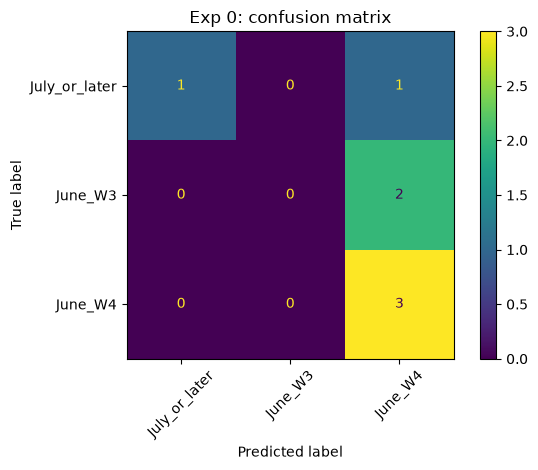

In [8]:
# Experiment 0 (single 80/20 split)
# no stratify=: June_W1 has only 1 year, and stratified splitting would crash
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=RS)

rf = RandomForestClassifier(n_estimators=200, random_state=RS).fit(X_tr, y_tr)
base = DummyClassifier(strategy='most_frequent').fit(X_tr, y_tr)

acc = accuracy_score(y_te, rf.predict(X_te))
base_acc = accuracy_score(y_te, base.predict(X_te))
print(f'Random Forest: {acc:.2f}   Always-guess baseline: {base_acc:.2f}   (test rows: {len(y_te)})')
log('Exp0 annual 80/20 split', acc)
log('Baseline (most frequent)', base_acc)

ConfusionMatrixDisplay.from_estimator(rf, X_te, y_te, xticks_rotation=45)
plt.title('Exp 0: confusion matrix')
plt.tight_layout()
plt.savefig('static/charts/exp0_confusion.png', dpi=150)
plt.show()

c:\Users\Samiksha\Desktop\aiml-cie\venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(
c:\Users\Samiksha\Desktop\aiml-cie\venv\Lib\site-packages\sklearn\model_selection\_split.py:812: UserWarning: The least populated class in y has only 1 members, which is less than n_splits=5.
  warnings.warn(


per fold: [0.29 0.33 0.17 0.   0.17]
mean 0.19 +/- 0.12   baseline 0.45


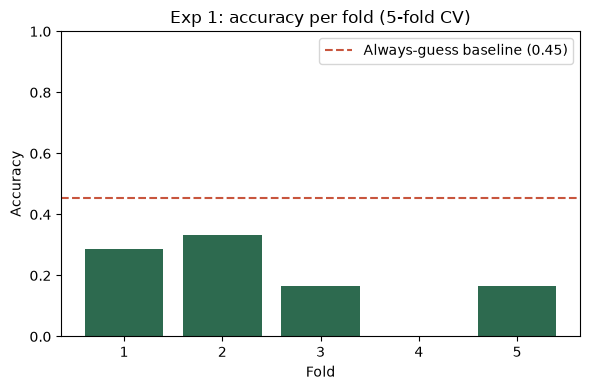

In [9]:
# Experiment 1 (5-fold cross-validation)
cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=RS)
scores = cross_val_score(RandomForestClassifier(n_estimators=200, random_state=RS), X, y, cv=cv, scoring='accuracy')
bscores = cross_val_score(DummyClassifier(strategy='most_frequent'), X, y, cv=cv, scoring='accuracy')
print('per fold:', scores.round(2))
print(f'mean {scores.mean():.2f} +/- {scores.std():.2f}   baseline {bscores.mean():.2f}')
log('Exp1 annual 5-fold', scores.mean(), scores.std())

plt.figure(figsize=(6, 4))
plt.bar(range(1, 6), scores, color='#2D6A4F')
plt.axhline(bscores.mean(), color='#C8553D', linestyle='--', label=f'Always-guess baseline ({bscores.mean():.2f})')
plt.xlabel('Fold'); plt.ylabel('Accuracy'); plt.ylim(0, 1)
plt.title('Exp 1: accuracy per fold (5-fold CV)')
plt.legend(); plt.tight_layout()
plt.savefig('static/charts/exp1_folds.png', dpi=150)
plt.show()

In [10]:
# temperory
labels = pd.read_csv('data/processed/labels.csv')
print(labels[labels.year.isin([2015, 2025])].to_string(index=False))

 year decision_date  cum_rain  future_rain  longest_dry_days  safe_label
 2015    2015-05-18       6.2         26.8                20           0
 2015    2015-05-25       6.2         77.6                13           0
 2015    2015-06-01       7.7        126.0                 6           0
 2015    2015-06-08      33.0        128.2                 4           0
 2015    2015-06-15      83.8         79.1                11           0
 2015    2015-06-22     133.7         31.0                18           0
 2015    2015-06-29     161.2          6.7                21           0
 2015    2015-07-06     162.9         14.1                15           0
 2015    2015-07-13     164.7         15.0                12           0
 2025    2025-05-18      44.5        224.5                 6           0
 2025    2025-05-25     146.3        174.3                 6           1
 2025    2025-06-01     255.8        118.3                 3           1
 2025    2025-06-08     269.0        123.7         

In [11]:
# temporory
w = pd.read_csv('data/raw/weather_daily.csv', parse_dates=['date']).set_index('date')
print(w.loc['2025-06-24':'2025-07-10', ['precipitation_sum', 'soil_moisture_0_to_7cm']].round(2))

            precipitation_sum  soil_moisture_0_to_7cm
date                                                 
2025-06-24                4.0                    0.46
2025-06-25                3.1                    0.47
2025-06-26                7.2                    0.47
2025-06-27                1.3                    0.47
2025-06-28                0.8                    0.45
2025-06-29                0.4                    0.42
2025-06-30                2.3                    0.42
2025-07-01               11.6                    0.43
2025-07-02                5.7                    0.42
2025-07-03                1.3                    0.43
2025-07-04                2.4                    0.41
2025-07-05                1.5                    0.42
2025-07-06                2.4                    0.45
2025-07-07               13.1                    0.49
2025-07-08                3.2                    0.48
2025-07-09                1.6                    0.48
2025-07-10                0.

In [12]:
# weekly data, two ways of testing
from sklearn.model_selection import KFold, GroupKFold, cross_validate, cross_val_predict

df = pd.read_csv('data/processed/final_dataset.csv')
FEATURES = ['doy', 'rain_7d', 'rain_14d', 'rain_cum_may1', 'rain_days_14d', 'days_since_rain',
            'tmax_7d', 'tmin_7d', 'soil_7d', 'rh_7d', 'et0_7d', 'oni', 'oni_change', 'dmi', 'soi']
X, y, groups = df[FEATURES], df['safe_label'], df['year']
base_acc = max(y.mean(), 1 - y.mean())          # accuracy of always guessing the common answer
print(X.shape, f'share safe: {y.mean():.3f}   baseline accuracy: {base_acc:.3f}')

rf = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RS)
scoring = ['accuracy', 'f1']
leaky = cross_validate(rf, X, y, cv=KFold(5, shuffle=True, random_state=RS), scoring=scoring)
honest = cross_validate(rf, X, y, cv=GroupKFold(n_splits=5), groups=groups, scoring=scoring)

for name, r in [('random split (leaky)', leaky), ('grouped by year (honest)', honest)]:
    print(f"{name}: accuracy {r['test_accuracy'].mean():.3f}   F1 {r['test_f1'].mean():.3f}")
    log(f'Exp2 {name} accuracy', r['test_accuracy'].mean(), r['test_accuracy'].std())
    log(f'Exp2 {name} F1', r['test_f1'].mean(), r['test_f1'].std())
log('Baseline weekly (always majority)', base_acc)

(279, 15) share safe: 0.326   baseline accuracy: 0.674
random split (leaky): accuracy 0.867   F1 0.828
grouped by year (honest): accuracy 0.857   F1 0.801


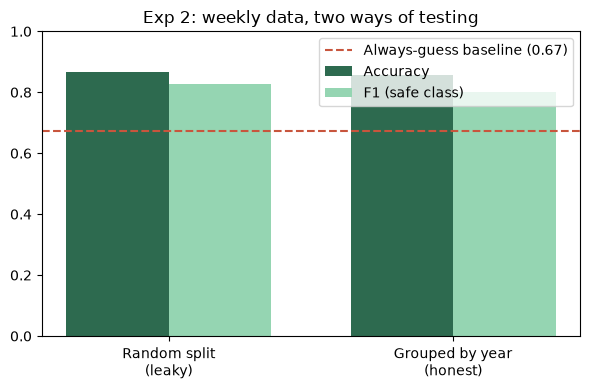

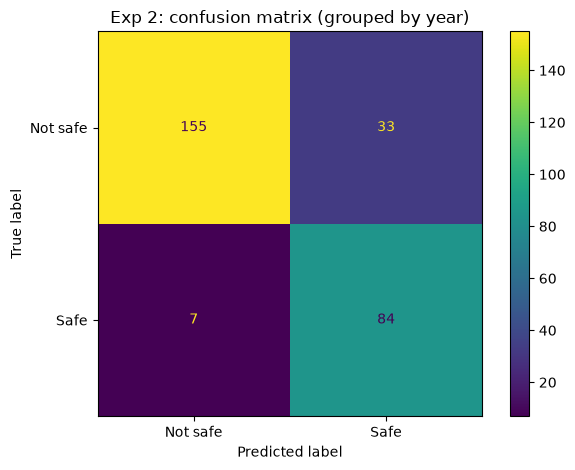

In [13]:
# charts
labels = ['Random split\n(leaky)', 'Grouped by year\n(honest)']
acc = [leaky['test_accuracy'].mean(), honest['test_accuracy'].mean()]
f1 = [leaky['test_f1'].mean(), honest['test_f1'].mean()]
x = np.arange(2)

plt.figure(figsize=(6, 4))
plt.bar(x - 0.18, acc, 0.36, label='Accuracy', color='#2D6A4F')
plt.bar(x + 0.18, f1, 0.36, label='F1 (safe class)', color='#95D5B2')
plt.axhline(base_acc, color='#C8553D', linestyle='--', label=f'Always-guess baseline ({base_acc:.2f})')
plt.xticks(x, labels); plt.ylim(0, 1)
plt.title('Exp 2: weekly data, two ways of testing')
plt.legend(); plt.tight_layout()
plt.savefig('static/charts/exp2_cv.png', dpi=150); plt.show()

pred = cross_val_predict(rf, X, y, cv=GroupKFold(n_splits=5), groups=groups)
ConfusionMatrixDisplay.from_predictions(y, pred, display_labels=['Not safe', 'Safe'])
plt.title('Exp 2: confusion matrix (grouped by year)')
plt.tight_layout()
plt.savefig('static/charts/exp2_confusion.png', dpi=150); plt.show()

Rule only (rain since 1 May >= 75 mm): accuracy 0.875  F1 0.839


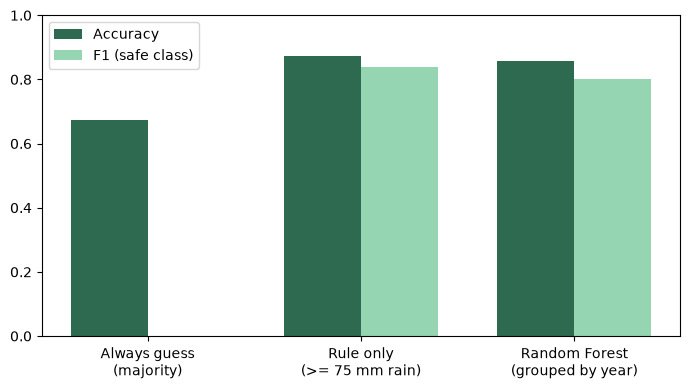

In [14]:
# test runs temporary
from sklearn.metrics import accuracy_score, f1_score

rule_pred = (df['rain_cum_may1'] >= 75).astype(int)
rule_acc, rule_f1 = accuracy_score(y, rule_pred), f1_score(y, rule_pred)
print(f'Rule only (rain since 1 May >= 75 mm): accuracy {rule_acc:.3f}  F1 {rule_f1:.3f}')
log('Rule-only baseline accuracy', rule_acc)
log('Rule-only baseline F1', rule_f1)

names = ['Always guess\n(majority)', 'Rule only\n(>= 75 mm rain)', 'Random Forest\n(grouped by year)']
acc = [base_acc, rule_acc, honest['test_accuracy'].mean()]
f1 = [0.0, rule_f1, honest['test_f1'].mean()]
x = np.arange(3)
plt.figure(figsize=(7, 4))
plt.bar(x - 0.18, acc, 0.36, label='Accuracy', color='#2D6A4F')
plt.bar(x + 0.18, f1, 0.36, label='F1 (safe class)', color='#95D5B2')
plt.xticks(x, names); plt.ylim(0, 1); plt.legend(); plt.tight_layout()
plt.savefig('static/charts/exp2_vs_rule.png', dpi=150); plt.show()

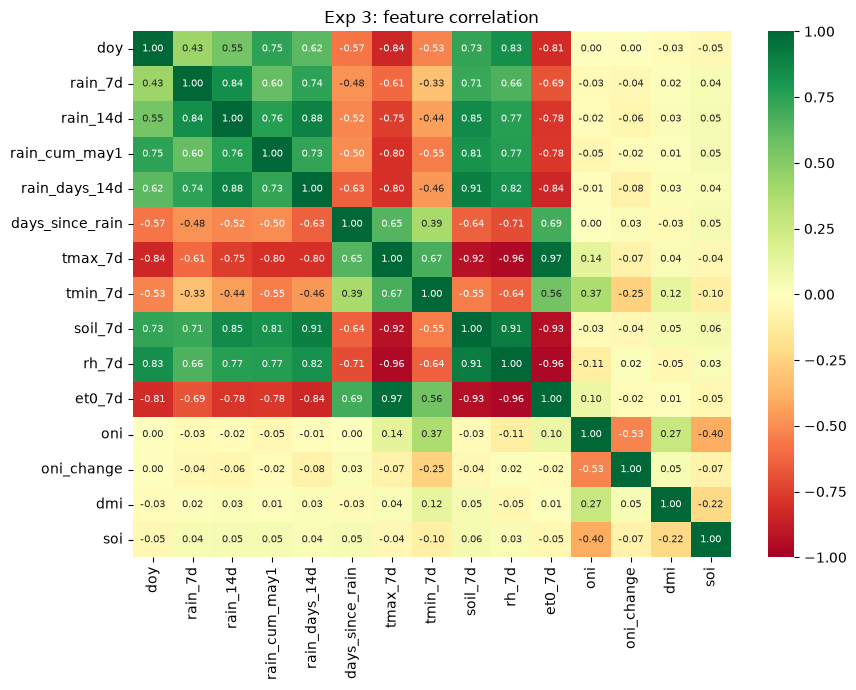

tmax_7d        et0_7d           0.97
rh_7d          et0_7d           0.96
tmax_7d        rh_7d            0.96
soil_7d        et0_7d           0.93
tmax_7d        soil_7d          0.92
soil_7d        rh_7d            0.91
rain_days_14d  soil_7d          0.91
rain_14d       rain_days_14d    0.88
               soil_7d          0.85
dtype: float64


In [15]:
# heatmap
import seaborn as sns
corr = X.corr()
plt.figure(figsize=(9, 7))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='RdYlGn', center=0, vmin=-1, vmax=1, annot_kws={'size': 7})
plt.title('Exp 3: feature correlation')
plt.tight_layout()
plt.savefig('static/charts/exp3_correlation.png', dpi=150); plt.show()

pairs = corr.abs().where(np.triu(np.ones(corr.shape), k=1).astype(bool)).stack()
print(pairs[pairs > 0.85].sort_values(ascending=False).round(2))   # near-duplicate features

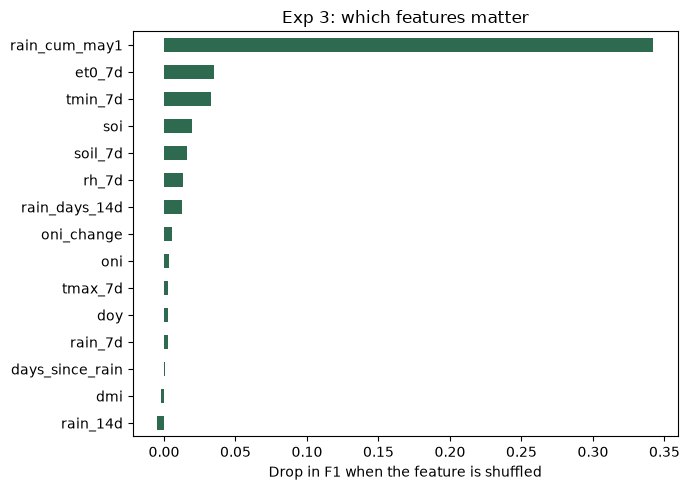

rain_cum_may1      0.342
et0_7d             0.035
tmin_7d            0.033
soi                0.020
soil_7d            0.016
rh_7d              0.014
rain_days_14d      0.013
oni_change         0.005
oni                0.004
tmax_7d            0.003
doy                0.003
rain_7d            0.003
days_since_rain    0.000
dmi               -0.002
rain_14d          -0.005
dtype: float64


In [16]:
# permutation importance
from sklearn.inspection import permutation_importance
imps = []
for tr, te in GroupKFold(n_splits=5).split(X, y, groups):
    m = RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RS).fit(X.iloc[tr], y.iloc[tr])
    r = permutation_importance(m, X.iloc[te], y.iloc[te], scoring='f1', n_repeats=10, random_state=RS)
    imps.append(r.importances_mean)
imp = pd.Series(np.mean(imps, axis=0), index=FEATURES).sort_values()

plt.figure(figsize=(7, 5))
imp.plot.barh(color='#2D6A4F')
plt.xlabel('Drop in F1 when the feature is shuffled'); plt.title('Exp 3: which features matter')
plt.tight_layout()
plt.savefig('static/charts/exp3_importance.png', dpi=150); plt.show()
print(imp.sort_values(ascending=False).round(3))

            feature set  accuracy    F1
        without rain_7d     0.860 0.807
            without doy     0.860 0.805
           All features     0.857 0.801
        without tmax_7d     0.857 0.801
            without oni     0.856 0.797
            without dmi     0.853 0.797
without days_since_rain     0.853 0.795
          without rh_7d     0.852 0.795
       without rain_14d     0.853 0.793
         without et0_7d     0.852 0.793
        without soil_7d     0.849 0.792
        without tmin_7d     0.850 0.791
  without rain_days_14d     0.849 0.789
            without soi     0.846 0.785
     without oni_change     0.846 0.783
  without rain_cum_may1     0.787 0.718
with climate indices: F1 0.801 | without: F1 0.758
Selected features: ['doy', 'rain_7d', 'rain_cum_may1', 'rain_days_14d', 'days_since_rain', 'tmax_7d', 'tmin_7d', 'soil_7d', 'rh_7d', 'et0_7d', 'oni', 'oni_change', 'soi']
selected: accuracy 0.868  F1 0.819


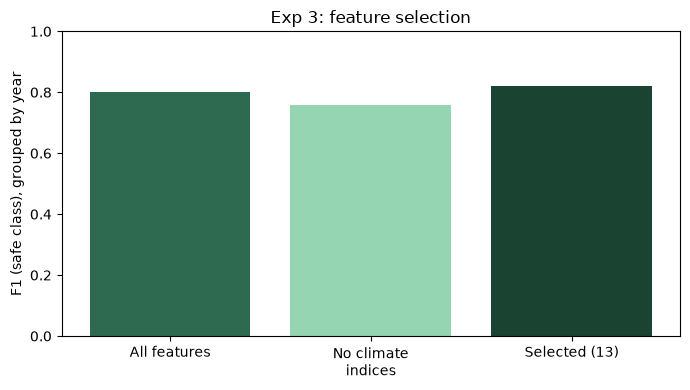

In [17]:
# Drop-column test, climate-index test and final set
def grouped_scores(cols):
    r = cross_validate(rf, df[cols], y, cv=GroupKFold(n_splits=5), groups=groups, scoring=['accuracy', 'f1'])
    return r['test_accuracy'].mean(), r['test_f1'].mean()

full = grouped_scores(FEATURES)
rows = [('All features', *full)] + [(f'without {f}', *grouped_scores([c for c in FEATURES if c != f])) for f in FEATURES]
print(pd.DataFrame(rows, columns=['feature set', 'accuracy', 'F1']).round(3).sort_values('F1', ascending=False).to_string(index=False))

CLIMATE = ['oni', 'oni_change', 'dmi', 'soi']
no_climate = grouped_scores([c for c in FEATURES if c not in CLIMATE])
print(f'with climate indices: F1 {full[1]:.3f} | without: F1 {no_climate[1]:.3f}')

FINAL = [f for f in FEATURES if imp[f] > 0]        # starting point: edit by hand after reading the tables
sel = grouped_scores(FINAL)
print('Selected features:', FINAL)
print(f'selected: accuracy {sel[0]:.3f}  F1 {sel[1]:.3f}')
log('Exp3 all features F1', full[1]); log('Exp3 without climate indices F1', no_climate[1]); log('Exp3 selected features F1', sel[1])

plt.figure(figsize=(7, 4))
plt.bar(['All features', 'No climate\nindices', f'Selected ({len(FINAL)})'], [full[1], no_climate[1], sel[1]],
        color=['#2D6A4F', '#95D5B2', '#1B4332'])
plt.ylim(0, 1); plt.ylabel('F1 (safe class), grouped by year'); plt.title('Exp 3: feature selection')
plt.tight_layout()
plt.savefig('static/charts/exp3_selection.png', dpi=150); plt.show()

In [18]:
# temporary test runs
from sklearn.metrics import confusion_matrix

rule_pred = (df['rain_cum_may1'] >= 75).astype(int)
rf_pred = cross_val_predict(rf, X, y, cv=GroupKFold(n_splits=5), groups=groups)
for name, p in [('Rule only', rule_pred), ('Random Forest', rf_pred)]:
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()
    print(f'{name}: correct safe {tp}, FALSE safe {fp}, missed safe {fn}, correct not-safe {tn}')

# false-start test: only the rows where the simple rule says "go"
S = df['rain_cum_may1'] >= 75
Xs, ys, gs = df.loc[S, FEATURES], y[S], groups[S]
print(f'rule says go on {S.sum()} rows; truly safe {ys.sum()} (rule right {ys.mean():.1%})')
rf_s = RandomForestClassifier(n_estimators=300, random_state=RS)
pred_s = cross_val_predict(rf_s, Xs, ys, cv=GroupKFold(n_splits=5), groups=gs)
tn, fp, fn, tp = confusion_matrix(ys, pred_s).ravel()
print(f'model right {(pred_s == ys).mean():.1%} | false starts caught {tn} of {tn + fp} | safe dates wrongly blocked {fn} of {fn + tp}')
log('False-start test: rule accuracy', ys.mean())
log('False-start test: model accuracy', (pred_s == ys).mean())


Rule only: correct safe 91, FALSE safe 35, missed safe 0, correct not-safe 153
Random Forest: correct safe 84, FALSE safe 33, missed safe 7, correct not-safe 155
rule says go on 126 rows; truly safe 91 (rule right 72.2%)
model right 64.3% | false starts caught 2 of 35 | safe dates wrongly blocked 12 of 91


In [19]:
# feature selection test:
SETS = {
    'All 15': FEATURES,
    'Selected 13': [f for f in FEATURES if f not in ['dmi', 'rain_14d']],
    'Compact 10': ['rain_cum_may1', 'rain_7d', 'rain_days_14d', 'days_since_rain', 'soil_7d',
                   'et0_7d', 'tmin_7d', 'oni', 'oni_change', 'soi'],
    'No heat/humidity group': [f for f in FEATURES if f not in ['tmax_7d', 'rh_7d', 'et0_7d', 'soil_7d']],
}
rows = [(name, *grouped_scores(cols)) for name, cols in SETS.items()]
print(pd.DataFrame(rows, columns=['feature set', 'accuracy', 'F1']).round(3).to_string(index=False))

           feature set  accuracy    F1
                All 15     0.857 0.801
           Selected 13     0.868 0.819
            Compact 10     0.875 0.829
No heat/humidity group     0.849 0.786


               model  accuracy    F1
Rule only (>= 75 mm)     0.875 0.839
      Majority guess     0.677 0.000
       Decision Tree     0.846 0.775
 Logistic Regression     0.824 0.746
       Random Forest     0.875 0.829


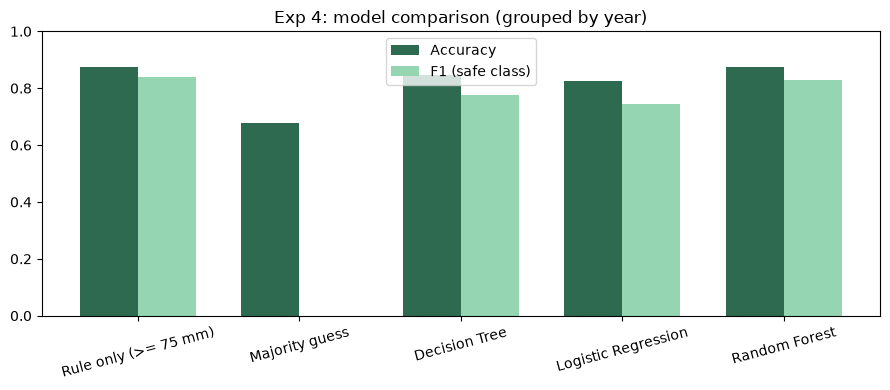

In [ ]:
# experiment 4: model comparison
# compare models on the Compact 10 set
from sklearn.tree import DecisionTreeClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.metrics import confusion_matrix

COMPACT = ['rain_cum_may1', 'rain_7d', 'rain_days_14d', 'days_since_rain', 'soil_7d',
           'et0_7d', 'tmin_7d', 'oni', 'oni_change', 'soi']
Xc = df[COMPACT]
rule_pred = (df['rain_cum_may1'] >= 75).astype(int)

models = {
    'Majority guess': DummyClassifier(strategy='most_frequent'),
    'Decision Tree': DecisionTreeClassifier(max_depth=4, class_weight='balanced', random_state=RS),
    'Logistic Regression': make_pipeline(SimpleImputer(strategy='median'), StandardScaler(),
                                         LogisticRegression(class_weight='balanced', max_iter=1000)),
    'Random Forest': RandomForestClassifier(n_estimators=300, class_weight='balanced', random_state=RS),
}
rows = [('Rule only (>= 75 mm)', accuracy_score(y, rule_pred), f1_score(y, rule_pred))]
for name, m in models.items():
    r = cross_validate(m, Xc, y, cv=GroupKFold(n_splits=5), groups=groups, scoring=['accuracy', 'f1'])
    rows.append((name, r['test_accuracy'].mean(), r['test_f1'].mean()))
comp = pd.DataFrame(rows, columns=['model', 'accuracy', 'F1']).round(3)
print(comp.to_string(index=False))
for _, row in comp.iterrows():
    log(f"Exp4 {row['model']} accuracy", row['accuracy'])
    log(f"Exp4 {row['model']} F1", row['F1'])

x = np.arange(len(comp))
plt.figure(figsize=(9, 4))
plt.bar(x - 0.18, comp['accuracy'], 0.36, label='Accuracy', color='#2D6A4F')
plt.bar(x + 0.18, comp['F1'], 0.36, label='F1 (safe class)', color='#95D5B2')
plt.xticks(x, comp['model'], rotation=15); plt.ylim(0, 1); plt.legend()
plt.title('Exp 4: model comparison (grouped by year)')
plt.tight_layout()
plt.savefig('static/charts/exp4_models.png', dpi=150); plt.show()

{'max_depth': 5, 'min_samples_leaf': 5, 'n_estimators': 200} 0.829
 cutoff  correct safe  FALSE safe  missed safe  precision  recall
    0.3            91          38            0      0.705   1.000
    0.4            91          36            0      0.717   1.000
    0.5            89          33            2      0.730   0.978
    0.6            85          32            6      0.726   0.934
    0.7            72          27           19      0.727   0.791
    0.8            44          16           47      0.733   0.484


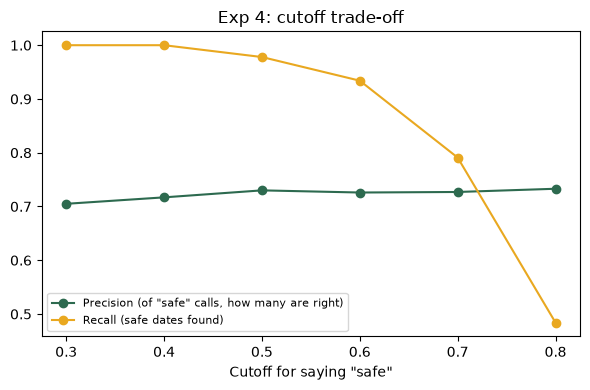

In [21]:
# light tuning and the cutoff trade-off
from sklearn.model_selection import GridSearchCV

grid = GridSearchCV(RandomForestClassifier(class_weight='balanced', random_state=RS),
                    {'n_estimators': [200, 400], 'max_depth': [3, 5, None], 'min_samples_leaf': [1, 3, 5]},
                    cv=GroupKFold(n_splits=5), scoring='f1', n_jobs=-1)
grid.fit(Xc, y, groups=groups)
print(grid.best_params_, round(grid.best_score_, 3))   # slightly optimistic: tuned on the same folds
best_rf = RandomForestClassifier(class_weight='balanced', random_state=RS, **grid.best_params_)
log('Exp4 tuned Random Forest F1', grid.best_score_)

proba = cross_val_predict(best_rf, Xc, y, cv=GroupKFold(n_splits=5), groups=groups, method='predict_proba')[:, 1]
rows = []
for t in [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]:
    p = (proba >= t).astype(int)
    tn, fp, fn, tp = confusion_matrix(y, p).ravel()
    rows.append((t, tp, fp, fn, round(tp / max(tp + fp, 1), 3), round(tp / (tp + fn), 3)))
thr = pd.DataFrame(rows, columns=['cutoff', 'correct safe', 'FALSE safe', 'missed safe', 'precision', 'recall'])
print(thr.to_string(index=False))

plt.figure(figsize=(6, 4))
plt.plot(thr['cutoff'], thr['precision'], marker='o', color='#2D6A4F', label='Precision (of "safe" calls, how many are right)')
plt.plot(thr['cutoff'], thr['recall'], marker='o', color='#E9A820', label='Recall (safe dates found)')
plt.xlabel('Cutoff for saying "safe"'); plt.legend(fontsize=8); plt.title('Exp 4: cutoff trade-off')
plt.tight_layout()
plt.savefig('static/charts/exp4_threshold.png', dpi=150); plt.show()


In [22]:
# train and save the final model and the website files
import joblib
final_model = best_rf.fit(Xc, y)
os.makedirs('models', exist_ok=True)
joblib.dump(final_model, 'models/best_model.joblib')
json.dump(COMPACT, open('models/features.json', 'w'))
json.dump(df[COMPACT].median().round(2).to_dict(), open('models/medians.json', 'w'))
json.dump(dict(zip(COMPACT, final_model.feature_importances_.round(3))), open('models/importances.json', 'w'))
print('saved:', os.listdir('models'))

saved: ['best_model.joblib', 'features.json', 'importances.json', 'medians.json']
